In [24]:
!pip install lazypredict

^C


In [1]:
import pandas as pd
import lazypredict
from lazypredict.Supervised import LazyClassifier
from sklearn.model_selection import train_test_split

# Correlation

NUMERIC COLUMNS (correlation with default)
              Column  Correlation
 no_checking_account       -0.322
months_loan_duration        0.215
              amount        0.155
     no_savings_info       -0.129
                 age       -0.091
     savings_balance       -0.075
    installment_rate        0.072
    existing_credits       -0.046
           has_phone       -0.036
    checking_balance       -0.027
          dependents       -0.003

TEXT COLUMNS (Cramers V and p-value)
           Column  Cramers_V  p_value        Useful?
   credit_history      0.248   0.0000            yes
employment_length      0.213   0.0454            yes
residence_history      0.187   0.5208 no (p >= 0.05)
          purpose      0.183   0.0001            yes
         property      0.154   0.0000            yes
          housing      0.135   0.0001            yes
 installment_plan      0.113   0.0016            yes
  personal_status      0.098   0.0222            yes
    other_debtors      0.082   0.0

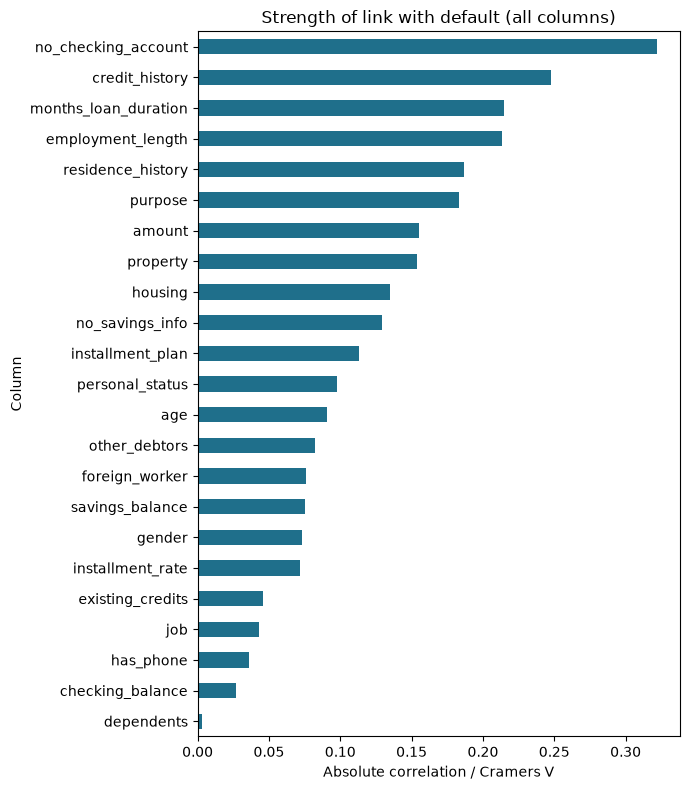

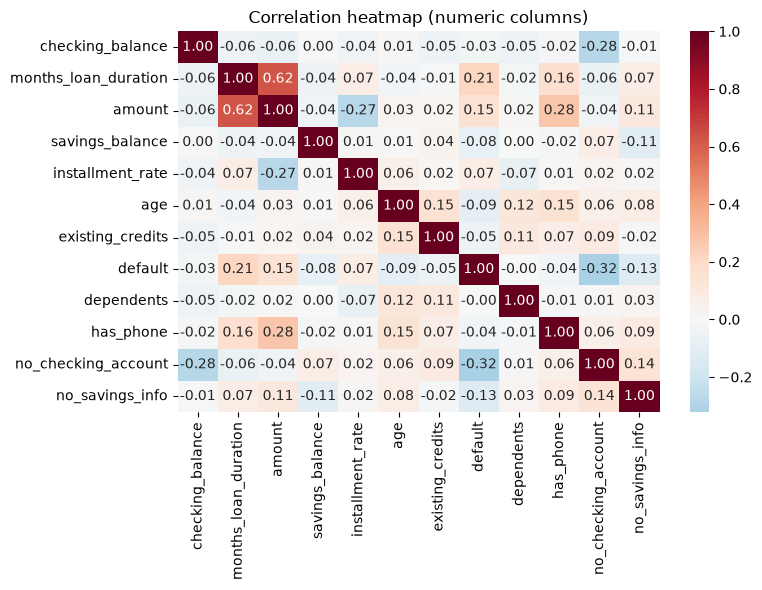

In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

# 1. Load a fresh copy and do the same light cleaning
raw = pd.read_csv('credit.csv')
raw['has_phone'] = raw['telephone'].notnull().astype(int)
raw['no_checking_account'] = raw['checking_balance'].isnull().astype(int)
raw['no_savings_info'] = raw['savings_balance'].isnull().astype(int)
raw = raw.drop(columns=['telephone', 'observation_id'])
raw['checking_balance'] = raw['checking_balance'].fillna(0)
raw['savings_balance'] = raw['savings_balance'].fillna(0)
for col in ['employment_length', 'personal_status', 'residence_history']:
    raw[col] = raw[col].fillna('unknown')

num_cols = raw.select_dtypes(include='number').columns.drop('default')
cat_cols = raw.select_dtypes(include=['object', 'string']).columns

# 2. Numeric columns: correlation with default
num_corr = raw[num_cols].corrwith(raw['default']).round(3)
num_table = pd.DataFrame({'Column': num_corr.index, 'Correlation': num_corr.values})
num_table = num_table.reindex(num_table['Correlation'].abs().sort_values(ascending=False).index)
print('NUMERIC COLUMNS (correlation with default)')
print(num_table.to_string(index=False))

# 3. Text columns: Cramer's V and p-value
def cramers_v(col):
    table = pd.crosstab(raw[col], raw['default'])
    chi2, p, _, _ = chi2_contingency(table)
    v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    return round(v, 3), round(p, 4)

cat_table = pd.DataFrame([(c, *cramers_v(c)) for c in cat_cols],
                         columns=['Column', 'Cramers_V', 'p_value'])
cat_table['Useful?'] = np.where(cat_table['p_value'] < 0.05, 'yes', 'no (p >= 0.05)')
cat_table = cat_table.sort_values('Cramers_V', ascending=False)
print('\nTEXT COLUMNS (Cramers V and p-value)')
print(cat_table.to_string(index=False))

# 4. Bar chart of all columns together
all_scores = pd.concat([num_table.set_index('Column')['Correlation'].abs().rename('strength'),
                        cat_table.set_index('Column')['Cramers_V'].rename('strength')]).sort_values()
plt.figure(figsize=(7, 8))
all_scores.plot.barh(color='#1F6F8B')
plt.title('Strength of link with default (all columns)')
plt.xlabel('Absolute correlation / Cramers V')
plt.tight_layout()
plt.show()

# 5. Heatmap of numeric columns (also shows if two inputs are duplicates)
plt.figure(figsize=(8, 6))
sns.heatmap(raw.select_dtypes(include='number').corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0)
plt.title('Correlation heatmap (numeric columns)')
plt.tight_layout()
plt.show()

# Preprocessing

In [2]:
data = pd.read_csv('credit.csv')

In [3]:
print(data.shape); 

(1000, 23)


In [4]:
print(data.isna().sum())

observation_id            0
checking_balance        394
months_loan_duration      0
credit_history            0
purpose                   0
amount                    0
savings_balance         183
employment_length        62
installment_rate          0
personal_status         310
other_debtors             0
residence_history       130
property                  0
age                       0
installment_plan          0
housing                   0
existing_credits          0
default                   0
dependents                0
telephone               596
foreign_worker            0
job                       0
gender                    0
dtype: int64


In [5]:
print(data.describe())

       observation_id  checking_balance  months_loan_duration        amount  \
count     1000.000000        606.000000           1000.000000   1000.000000   
mean       499.500000         97.245875             20.903000   3271.258000   
std        288.819436        206.923583             12.058814   2822.736876   
min          0.000000        -50.000000              4.000000    250.000000   
25%        249.750000        -23.000000             12.000000   1365.500000   
50%        499.500000         24.000000             18.000000   2319.500000   
75%        749.250000        131.750000             24.000000   3972.250000   
max        999.000000        999.000000             72.000000  18424.000000   

       savings_balance  installment_rate          age  existing_credits  \
count       817.000000       1000.000000  1000.000000       1000.000000   
mean        781.570379          2.973000    35.546000          1.407000   
std        3016.983785          1.118715    11.375469          

In [6]:
data['has_phone'] = data['telephone'].notnull().astype(int)
data = data.drop(columns=['telephone', 'observation_id'])

data['checking_balance'] = data['checking_balance'].fillna(0)
data['savings_balance'] = data['savings_balance'].fillna(0)

for col in ['employment_length', 'personal_status', 'residence_history']:
    data[col] = data[col].fillna('unknown')

print(data.isnull().sum())

checking_balance        0
months_loan_duration    0
credit_history          0
purpose                 0
amount                  0
savings_balance         0
employment_length       0
installment_rate        0
personal_status         0
other_debtors           0
residence_history       0
property                0
age                     0
installment_plan        0
housing                 0
existing_credits        0
default                 0
dependents              0
foreign_worker          0
job                     0
gender                  0
has_phone               0
dtype: int64


In [7]:
data = data.drop(columns=['dependents', 'job', 'residence_history', 'has_phone',
                          'gender', 'personal_status'])

In [8]:
data = pd.get_dummies(data, drop_first=True, dtype=int)

In [10]:

X = data.drop(['default'], axis=1)
y = data['default']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

clf = LazyClassifier(verbose=0, ignore_warnings=True, custom_metric=None)
models, predictions = clf.fit(X_train, X_test, y_train, y_test)

print(models)

                               Accuracy  Balanced Accuracy   ROC AUC  \
Model                                                                  
XGBClassifier                     0.790           0.708138  0.806948   
AdaBoostClassifier                0.770           0.679168  0.773230   
RandomForestClassifier            0.755           0.614317  0.783027   
NearestCentroid                   0.630           0.604520  0.630004   
BaggingClassifier                 0.710           0.597187  0.740894   
QuadraticDiscriminantAnalysis     0.630           0.589734  0.556858   
GaussianNB                        0.595           0.584626  0.534319   
DecisionTreeClassifier            0.650           0.584205  0.584205   
LogisticRegression                0.685           0.579457  0.643587   
RidgeClassifier                   0.690           0.578074  0.651400   
RidgeClassifierCV                 0.690           0.578074  0.651400   
NuSVC                             0.690           0.573146  0.67

In [11]:
print(X.isnull().sum())

checking_balance           0
months_loan_duration       0
amount                     0
savings_balance            0
installment_rate           0
                          ..
installment_plan_none      0
installment_plan_stores    0
housing_own                0
housing_rent               0
foreign_worker_yes         0
Length: 61, dtype: int64


# Splitting

In [12]:
X = data.drop('default', axis=1)   
y = data['default']                

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print(X_train.shape, X_test.shape)

(800, 61) (200, 61)


# Scaling

In [13]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # learn from training data only
X_test_scaled = scaler.transform(X_test)         # apply the same scaling to test

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, recall_score, f1_score, roc_auc_score

In [15]:
probs = {}
preds = {}

# Logistic Regression

In [16]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression

# The settings to try
param_grid = {
    'C': [0.001, 0.01, 0.03, 0.1, 0.3, 1, 3, 10],
    'penalty': ['l1', 'l2'],
    'solver': ['liblinear']      # works with both penalty types
}

grid_lr = GridSearchCV(
    LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42),
    param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1)

grid_lr.fit(X_train_scaled, y_train)

print('Best settings:', grid_lr.best_params_)
print('Best CV F1:', round(grid_lr.best_score_, 3))

Best settings: {'C': 1, 'penalty': 'l2', 'solver': 'liblinear'}
Best CV F1: 0.557


In [18]:
model = LogisticRegression(max_iter=1000, class_weight='balanced', C=1, penalty='l2', solver='liblinear', random_state=42)
model.fit(X_train_scaled, y_train)

pred = model.predict(X_test_scaled)
prob = model.predict_proba(X_test_scaled)[:, 1]

resultsLR = {
    'Accuracy': accuracy_score(y_test, pred),
    'Recall': recall_score(y_test, pred),
    'F1': f1_score(y_test, pred),
    'AUC': roc_auc_score(y_test, prob)}
print(resultsLR)

probs['Logistic Regression'] = prob
preds['Logistic Regression'] = pred

{'Accuracy': 0.675, 'Recall': 0.6833333333333333, 'F1': 0.5578231292517006, 'AUC': 0.731547619047619}


# Decission Tree

In [19]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier

# The settings to try
param_grid = {
    'max_depth': [2, 3, 4, 5, 6, 8],
    'min_samples_leaf': [5, 10, 20, 30, 50],
    'min_samples_split': [2, 10, 30],
    'criterion': ['gini', 'entropy']
}

grid_dt = GridSearchCV(
    DecisionTreeClassifier(class_weight='balanced', random_state=42),
    param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1)

grid_dt.fit(X_train_scaled, y_train)

print('Best settings:', grid_dt.best_params_)
print('Best CV F1:', round(grid_dt.best_score_, 3))

Best settings: {'criterion': 'entropy', 'max_depth': 3, 'min_samples_leaf': 30, 'min_samples_split': 2}
Best CV F1: 0.553


In [20]:
model = DecisionTreeClassifier(max_depth=3, min_samples_leaf=30, 
min_samples_split=2, criterion='entropy', class_weight='balanced', random_state=42)

model.fit(X_train_scaled, y_train)

pred = model.predict(X_test_scaled)
prob = model.predict_proba(X_test_scaled)[:, 1]

resultsDT = {
    'Accuracy': accuracy_score(y_test, pred),
    'Recall': recall_score(y_test, pred),
    'F1': f1_score(y_test, pred),
    'AUC': roc_auc_score(y_test, prob)}
print(resultsDT)

probs['Decision Tree'] = prob
preds['Decision Tree'] = pred

{'Accuracy': 0.605, 'Recall': 0.7333333333333333, 'F1': 0.5269461077844312, 'AUC': 0.7158928571428571}


# Random Forest

In [21]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

# The settings to try (keep the lists short so it runs fast)
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [4, 6, 8, None],
    'min_samples_leaf': [1, 3, 5]
}

grid = GridSearchCV(
    RandomForestClassifier(class_weight='balanced', random_state=42),
    param_grid,
    cv=5,              # test each combination 5 times on different slices of the training data
    scoring='f1',      # what "best" means
    n_jobs=-1)         # use all CPU cores

grid.fit(X_train_scaled, y_train)

print('Best settings:', grid.best_params_)
print('Best CV F1:', round(grid.best_score_, 3))

Best settings: {'max_depth': 6, 'min_samples_leaf': 5, 'n_estimators': 300}
Best CV F1: 0.599


In [25]:
model = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, 
max_depth=6, class_weight='balanced', random_state=42)

model.fit(X_train_scaled, y_train)

prob = model.predict_proba(X_test_scaled)[:, 1]      # risk probability for each applicant
pred = (prob >= 0.4).astype(int) 

resultsRF = {
    'Accuracy': accuracy_score(y_test, pred),
    'Recall': recall_score(y_test, pred),
    'F1': f1_score(y_test, pred),
    'AUC': roc_auc_score(y_test, prob)}
print(resultsRF)

probs['Random Forest'] = prob
preds['Random Forest'] = pred

{'Accuracy': 0.575, 'Recall': 0.8833333333333333, 'F1': 0.5549738219895288, 'AUC': 0.7877380952380951}


# SVM

In [26]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC

# The settings to try
param_grid = {
    'C': [0.1, 0.3, 1, 3, 10],
    'gamma': ['scale', 0.001, 0.003, 0.01],
    'kernel': ['rbf', 'linear']
}

grid_svm = GridSearchCV(
    SVC(class_weight='balanced', random_state=42),
    param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1)

grid_svm.fit(X_train_scaled, y_train)

print('Best settings:', grid_svm.best_params_)
print('Best CV F1:', round(grid_svm.best_score_, 3))

Best settings: {'C': 10, 'gamma': 0.003, 'kernel': 'rbf'}
Best CV F1: 0.555


In [27]:
model = SVC(probability=True, class_weight='balanced', random_state=42, C=10, gamma=0.003, kernel='rbf')
model.fit(X_train_scaled, y_train)

pred = model.predict(X_test_scaled)
prob = model.predict_proba(X_test_scaled)[:, 1]

resultsSVM = {
    'Accuracy': accuracy_score(y_test, pred),
    'Recall': recall_score(y_test, pred),
    'F1': f1_score(y_test, pred),
    'AUC': roc_auc_score(y_test, prob)}
print(resultsSVM)

probs['SVM'] = prob
preds['SVM'] = pred

{'Accuracy': 0.665, 'Recall': 0.6833333333333333, 'F1': 0.5503355704697986, 'AUC': 0.7411309523809524}


# XG Boost

In [28]:
from sklearn.model_selection import GridSearchCV
from xgboost import XGBClassifier

# Same class-balance setting as before
ratio = (y_train == 0).sum() / (y_train == 1).sum()

# The settings to try (kept short so it runs fast)
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [2, 3, 4],
    'learning_rate': [0.03, 0.05, 0.1],
    'subsample': [0.8, 1.0]
}

grid_xgb = GridSearchCV(
    XGBClassifier(scale_pos_weight=ratio, random_state=42, eval_metric='logloss'),
    param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1)

grid_xgb.fit(X_train_scaled, y_train)

print('Best settings:', grid_xgb.best_params_)
print('Best CV F1:', round(grid_xgb.best_score_, 3))

Best settings: {'learning_rate': 0.03, 'max_depth': 4, 'n_estimators': 300, 'subsample': 0.8}
Best CV F1: 0.587


In [29]:
from xgboost import XGBClassifier

# XGBoost's version of class_weight='balanced'
ratio = (y_train == 0).sum() / (y_train == 1).sum()

model = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.03, subsample=0.8,
                      scale_pos_weight=ratio, random_state=42, eval_metric='logloss')
model.fit(X_train_scaled, y_train)

pred = model.predict(X_test_scaled)
prob = model.predict_proba(X_test_scaled)[:, 1]

resultsXGBoost = {
    'Accuracy': accuracy_score(y_test, pred),
    'Recall': recall_score(y_test, pred),
    'F1': f1_score(y_test, pred),
    'AUC': roc_auc_score(y_test, prob)}
print(resultsXGBoost)

probs['XGBoost'] = prob
preds['XGBoost'] = pred

{'Accuracy': 0.745, 'Recall': 0.6833333333333333, 'F1': 0.6165413533834586, 'AUC': 0.7788095238095238}


# AUC and ROC

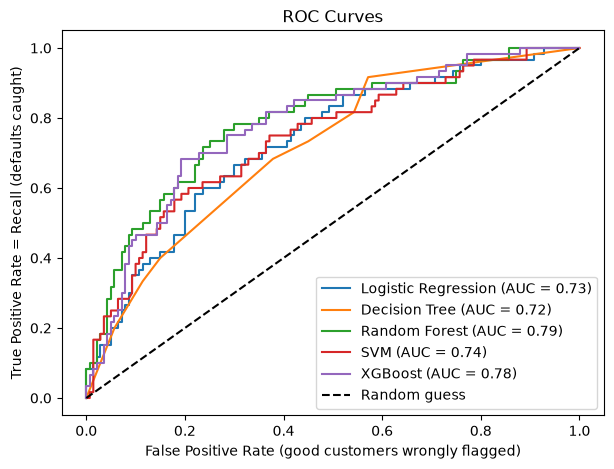

In [30]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

plt.figure(figsize=(7, 5))

for name, prob in probs.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.2f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random guess')   # diagonal line
plt.xlabel('False Positive Rate (good customers wrongly flagged)')
plt.ylabel('True Positive Rate = Recall (defaults caught)')
plt.title('ROC Curves')
plt.legend()
plt.show()

# Confusion Matrix

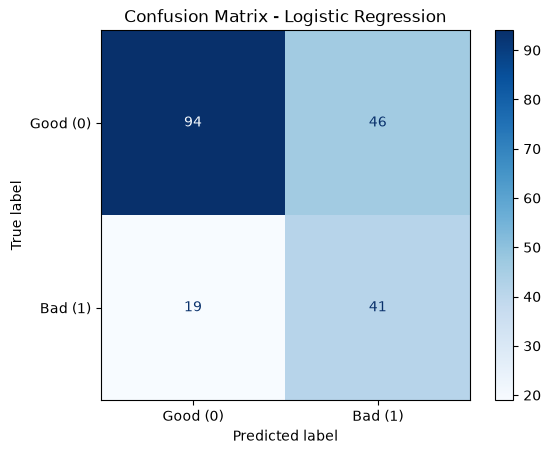

In [31]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, preds['Logistic Regression'])   # change the name to your best model
ConfusionMatrixDisplay(cm, display_labels=['Good (0)', 'Bad (1)']).plot(cmap='Blues')
plt.title('Confusion Matrix - Logistic Regression')
plt.show()

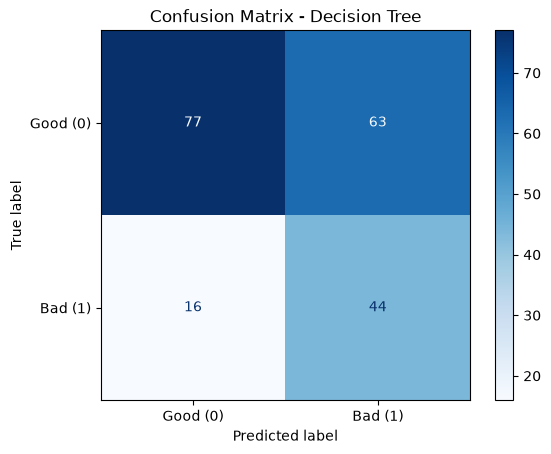

In [31]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, preds['Decision Tree'])   # change the name to your best model
ConfusionMatrixDisplay(cm, display_labels=['Good (0)', 'Bad (1)']).plot(cmap='Blues')
plt.title('Confusion Matrix - Decision Tree')
plt.show()

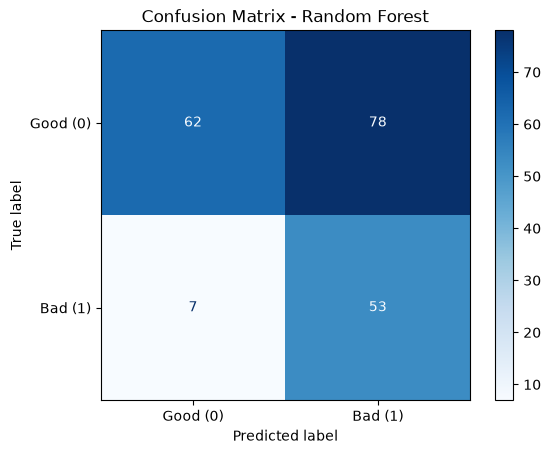

In [32]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, preds['Random Forest'])   # change the name to your best model
ConfusionMatrixDisplay(cm, display_labels=['Good (0)', 'Bad (1)']).plot(cmap='Blues')
plt.title('Confusion Matrix - Random Forest')
plt.show()

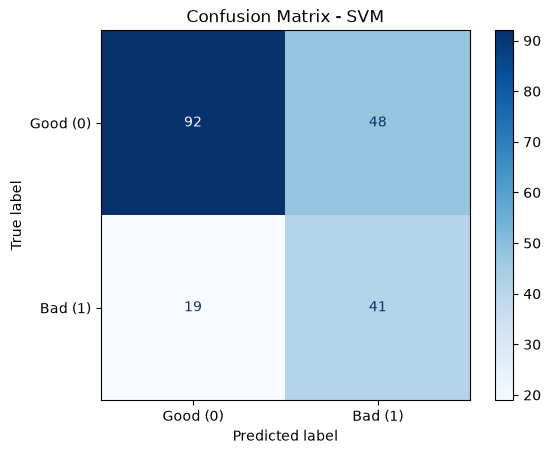

In [33]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, preds['SVM'])   # change the name to your best model
ConfusionMatrixDisplay(cm, display_labels=['Good (0)', 'Bad (1)']).plot(cmap='Blues')
plt.title('Confusion Matrix - SVM')
plt.show()

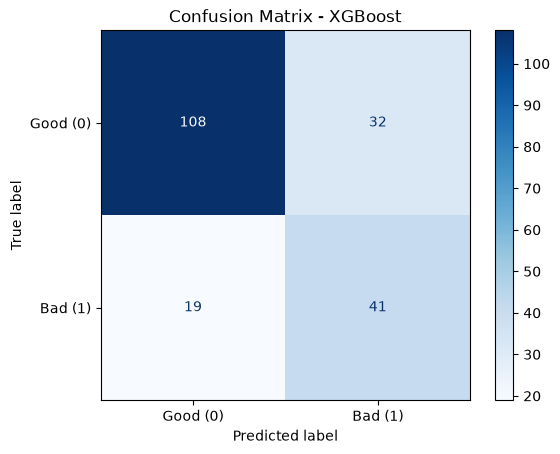

In [34]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, preds['XGBoost'])   # change the name to your best model
ConfusionMatrixDisplay(cm, display_labels=['Good (0)', 'Bad (1)']).plot(cmap='Blues')
plt.title('Confusion Matrix - XGBoost')
plt.show()